In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from ucimlrepo import fetch_ucirepo
from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, roc_auc_score, confusion_matrix, roc_curve

In [7]:
# 1. Data Acquisition
print("Fetching Heart Disease dataset from UCI...")
heart_disease = fetch_ucirepo(id=45)
X = heart_disease.data.features
y = heart_disease.data.targets

# The target 'num' in UCI dataset has values 0 (no disease) and 1-4 (presence).
# Convert to binary classification (0 = absence, 1 = presence)
y = (y['num'] > 0).astype(int)

df = pd.concat([X, y.rename('target')], axis=1)

Fetching Heart Disease dataset from UCI...


/var/folders/3q/tjk6jrz14zg_sr3h1lzmly980000gn/T/ipykernel_70554/952628186.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='target', data=df, palette='viridis')


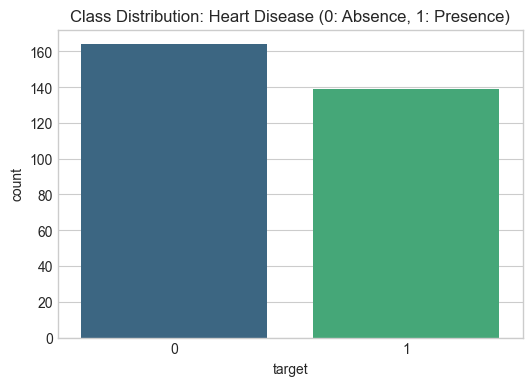

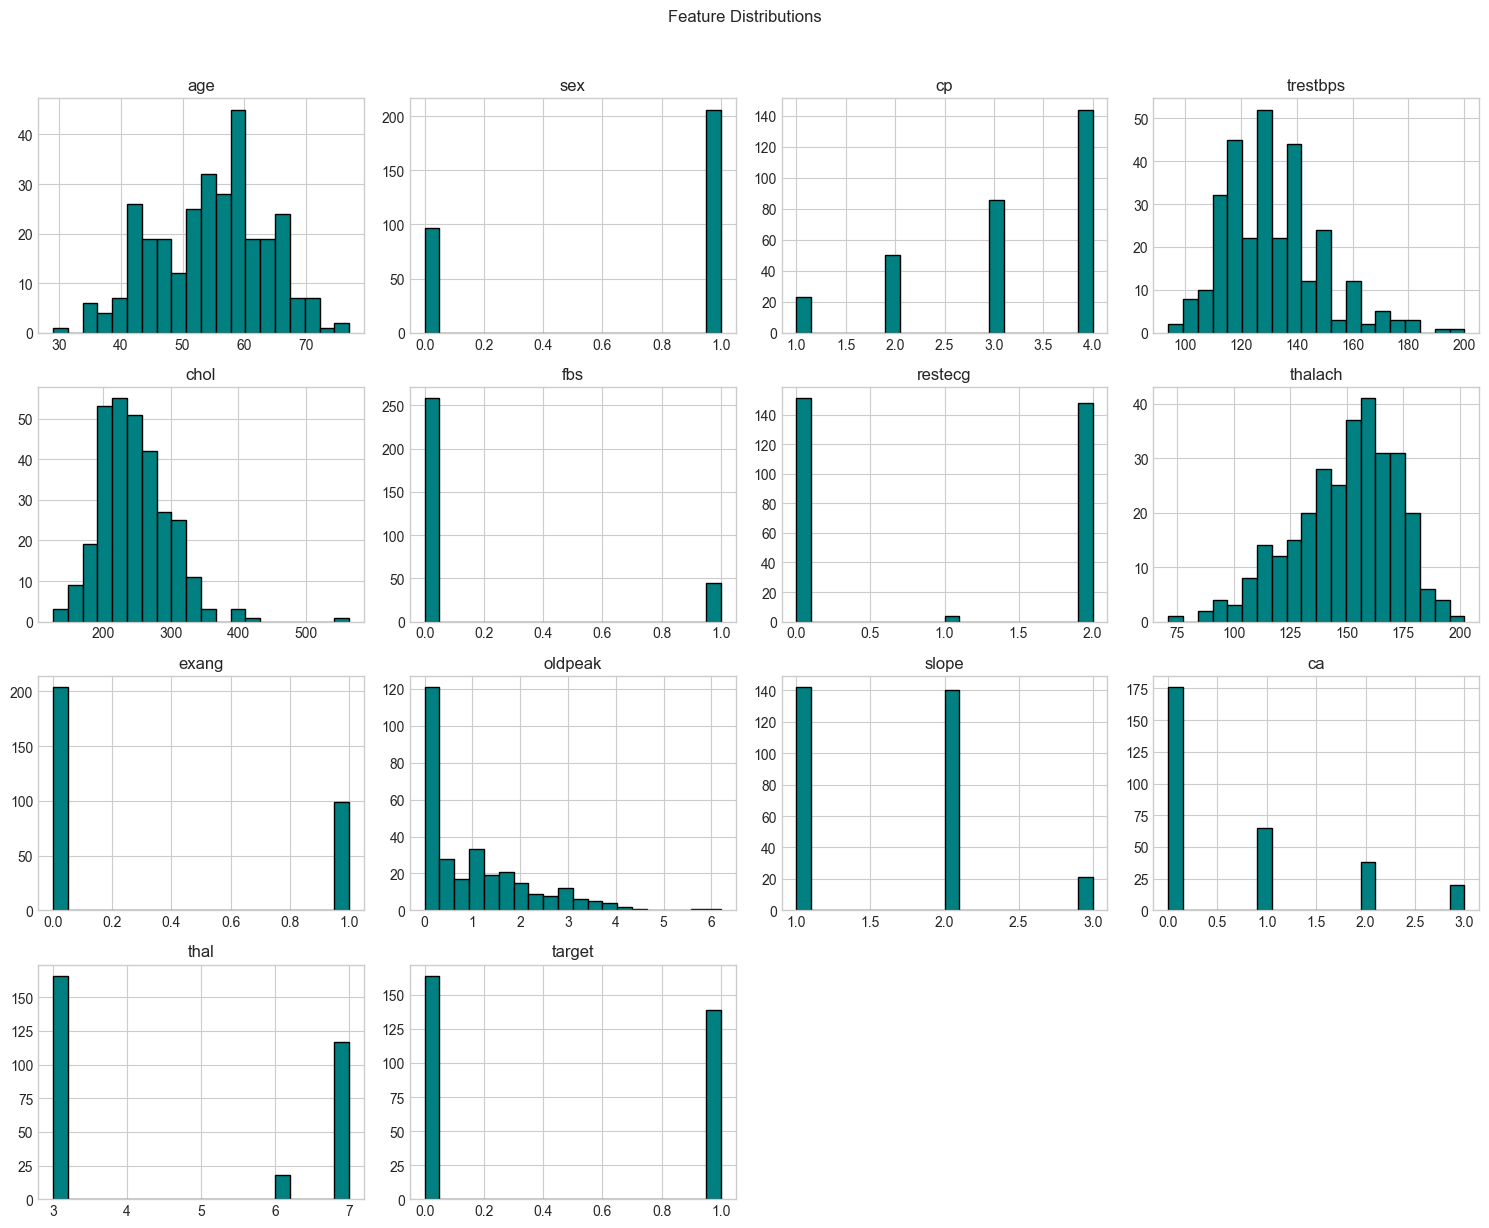

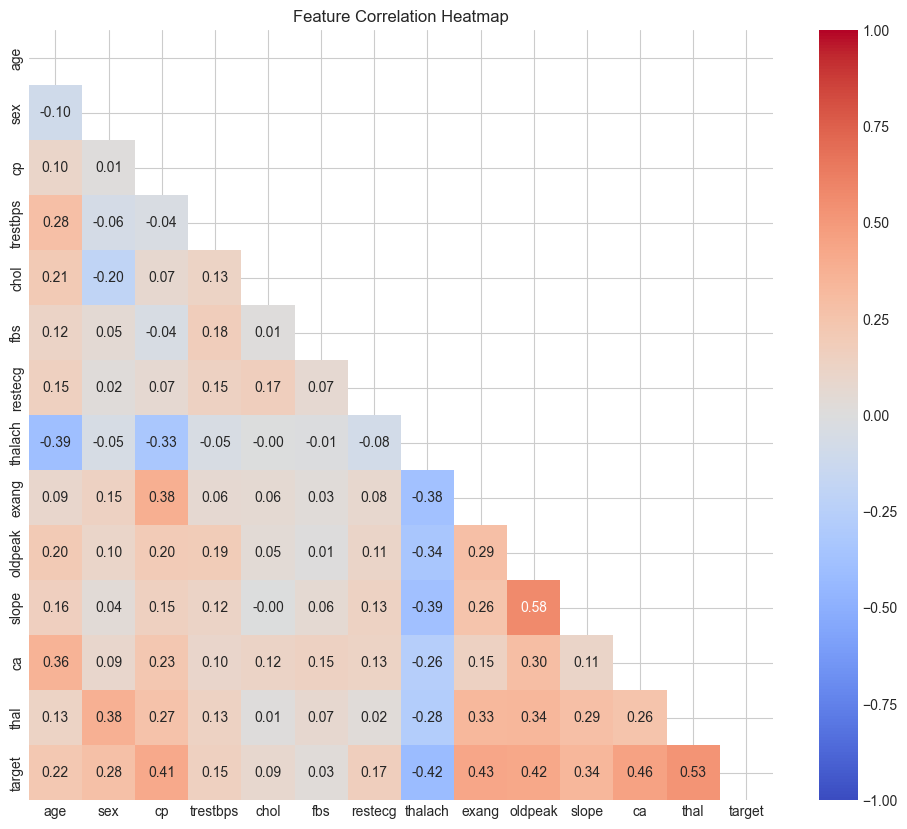

In [8]:
# 2. EDA & Visualizations
plt.style.use('seaborn-v0_8-whitegrid')

# Fig 1: Class Balance
plt.figure(figsize=(6, 4))
sns.countplot(x='target', data=df, palette='viridis')
plt.title('Class Distribution: Heart Disease (0: Absence, 1: Presence)')
plt.show()

# Fig 2: Feature Histograms
df.hist(figsize=(15, 12), bins=20, color='teal', edgecolor='black')
plt.suptitle('Feature Distributions', y=1.02)
plt.tight_layout()
plt.show()

# Fig 3: Correlation Heatmap
plt.figure(figsize=(12, 10))
corr = df.corr()
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Feature Correlation Heatmap')
plt.show()


--- Training Logistic Regression ---


/Users/abhijitroy/my-ml-project/.venv/lib/python3.9/site-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [3] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/Users/abhijitroy/my-ml-project/.venv/lib/python3.9/site-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [3] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/Users/abhijitroy/my-ml-project/.venv/lib/python3.9/site-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [3] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/Users/abhijitroy/my-ml-project/.venv/lib/python3.9/site-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [3] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/Users/a

Best LR Params: {'classifier__C': 1}

--- Training Random Forest ---


/Users/abhijitroy/my-ml-project/.venv/lib/python3.9/site-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [3] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/Users/abhijitroy/my-ml-project/.venv/lib/python3.9/site-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [3] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/Users/abhijitroy/my-ml-project/.venv/lib/python3.9/site-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [3] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/Users/abhijitroy/my-ml-project/.venv/lib/python3.9/site-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [3] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/Users/a

Best RF Params: {'classifier__max_depth': 10, 'classifier__min_samples_split': 5, 'classifier__n_estimators': 100}

================ Logistic Regression ===============
Classification Report:
              precision    recall  f1-score   support

           0       0.90      0.82      0.86        33
           1       0.81      0.89      0.85        28

    accuracy                           0.85        61
   macro avg       0.85      0.86      0.85        61
weighted avg       0.86      0.85      0.85        61

ROC-AUC Score: 0.9567

================ Random Forest ===============
Classification Report:
              precision    recall  f1-score   support

           0       0.91      0.88      0.89        33
           1       0.86      0.89      0.88        28

    accuracy                           0.89        61
   macro avg       0.88      0.89      0.88        61
weighted avg       0.89      0.89      0.89        61

ROC-AUC Score: 0.9556


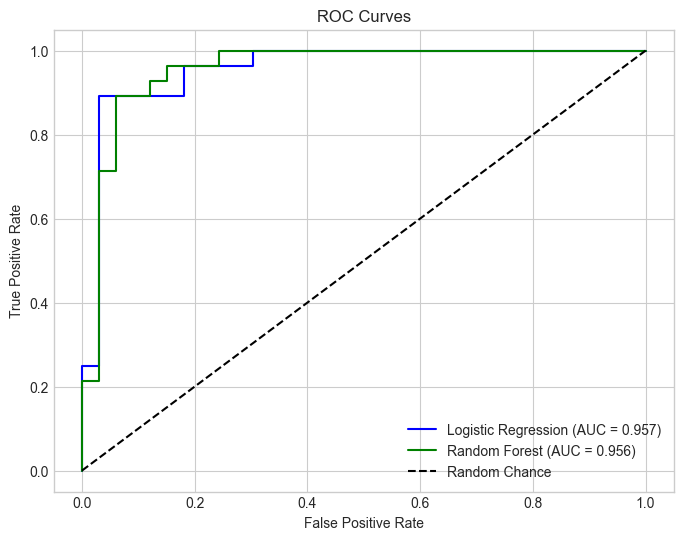

In [9]:
# ==========================================
# Task 2: Feature Engineering & Modeling
# ==========================================

# 1. Feature Engineering Setup
# Identify categorical and numerical columns based on UCI description
categorical_cols = ['sex', 'cp', 'fbs', 'restecg', 'exang', 'slope', 'thal']
numerical_cols = ['age', 'trestbps', 'chol', 'thalach', 'oldpeak', 'ca']

# Build Preprocessing Pipelines
numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore', drop='first'))
])

preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numerical_cols),
        ('cat', categorical_transformer, categorical_cols)
    ])

# 2. Train-Test Split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# 3. Model Definition & Pipeline
log_reg = Pipeline(steps=[('preprocessor', preprocessor),
                          ('classifier', LogisticRegression(max_iter=1000))])

rf_clf = Pipeline(steps=[('preprocessor', preprocessor),
                         ('classifier', RandomForestClassifier(random_state=42))])

# 4. Hyperparameter Tuning (GridSearchCV)
print("\n--- Training Logistic Regression ---")
log_param_grid = {'classifier__C': [0.01, 0.1, 1, 10, 100]}
log_grid = GridSearchCV(log_reg, log_param_grid, cv=5, scoring='roc_auc', n_jobs=-1)
log_grid.fit(X_train, y_train)
print(f"Best LR Params: {log_grid.best_params_}")

print("\n--- Training Random Forest ---")
rf_param_grid = {
    'classifier__n_estimators': [50, 100, 200],
    'classifier__max_depth': [None, 5, 10],
    'classifier__min_samples_split': [2, 5]
}
rf_grid = GridSearchCV(rf_clf, rf_param_grid, cv=5, scoring='roc_auc', n_jobs=-1)
rf_grid.fit(X_train, y_train)
print(f"Best RF Params: {rf_grid.best_params_}")

# 5. Model Evaluation
def evaluate_model(model, name):
    y_pred = model.predict(X_test)
    y_proba = model.predict_proba(X_test)[:, 1]
    
    print(f"\n================ {name} ===============")
    print("Classification Report:")
    print(classification_report(y_test, y_pred))
    
    auc = roc_auc_score(y_test, y_proba)
    print(f"ROC-AUC Score: {auc:.4f}")
    
    # ROC Curve Plotting
    fpr, tpr, _ = roc_curve(y_test, y_proba)
    return fpr, tpr, auc

fpr_lr, tpr_lr, auc_lr = evaluate_model(log_grid.best_estimator_, "Logistic Regression")
fpr_rf, tpr_rf, auc_rf = evaluate_model(rf_grid.best_estimator_, "Random Forest")

# Fig 4: ROC Curves
plt.figure(figsize=(8, 6))
plt.plot(fpr_lr, tpr_lr, label=f'Logistic Regression (AUC = {auc_lr:.3f})', color='blue')
plt.plot(fpr_rf, tpr_rf, label=f'Random Forest (AUC = {auc_rf:.3f})', color='green')
plt.plot([0, 1], [0, 1], 'k--', label='Random Chance')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curves')
plt.legend()
plt.show()

In [15]:
import pickle
model = log_grid.best_estimator_
with open("model.pkl", "wb") as file:
    pickle.dump(model, file)